In [13]:
import pandas as pd 
from statsforecast import StatsForecast

from statsforecast.models import (
    AutoARIMA,
    MSTL,
)

In [3]:
#importing and reading the ambulance response data
df = pd.read_csv("data/Daily_Responses_5_Years_2019_full.csv")
df.head()

,ds,y,area
0,2013-12-30,220,Cornwall
1,2013-12-30,129,Gloucestershire
2,2013-12-30,255,Wiltshire
3,2013-12-30,2042,Trust
4,2013-12-30,336,Dorset


In [ ]:
#renaming area column to allow forecasting to work
df_rename = df.rename(columns={'area':'unique_id'}).copy()
df_rename.head()
#filtering to Trust area
Trust = df_rename[df_rename["unique_id"]=="Trust"]


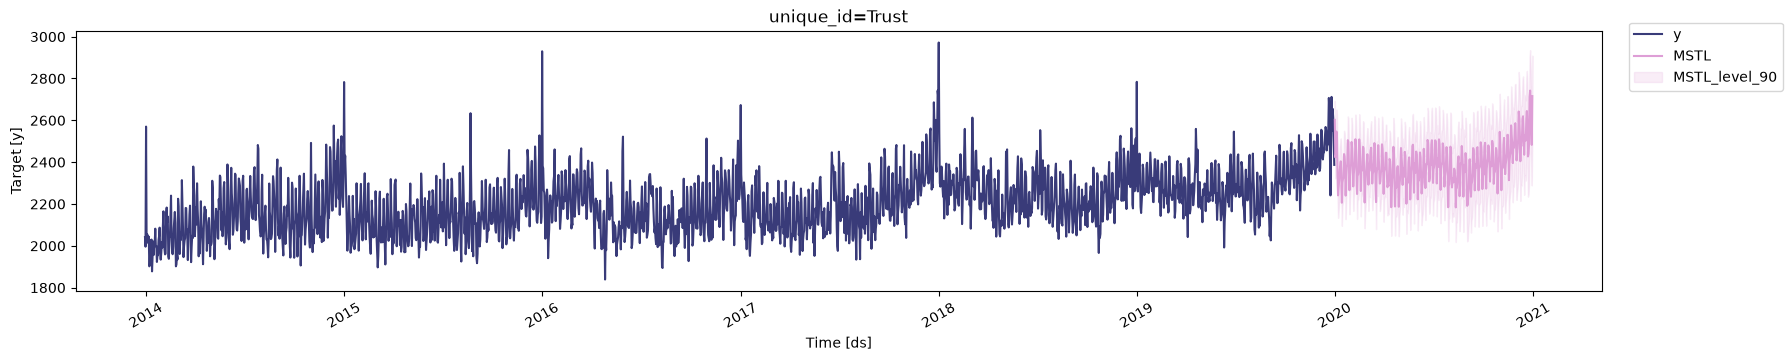

In [49]:
# making the fitted model
models = [MSTL(
    season_length=[7,365],
    trend_forecaster=AutoARIMA()
)]

sf = StatsForecast(
    models=models,
    freq='D'
)
sf.fit(df=Trust)

# making the predicted model
forecast_df = sf.predict(
    h=365, level=[90]
)
forecast_df.tail()

# plot the forecast
sf.plot(Trust,forecast_df, level=[90])
